# Stage 7.2–7.3 — Final evaluation on the locked test years (2020–2025) and statistical comparison

The researcher confirmed the final evaluation. `src/final_eval.py` was run **once** with `confirm_final=True` from the freeze
commit (`55d416f`); it refitted every frozen model on 1981–2019 and wrote the test predictions to `models/test/` with a
manifest. This notebook only **reads** those predictions (it refits nothing) and applies the pre-registered protocol of
`final_config.yaml`. Analysis code: `src/final_report.py`.

### Step 1 — Setup and the run manifest

**WHAT:** imports; read `models/test/manifest.json`; check that it was produced from the freeze commit with the frozen config
(SHA-256), that every expected model × seed file exists and covers the 2,192 test days.

**WHY:** the paper must be able to state that the reported numbers are the one-shot output of the committed protocol.

**Look for:** commit `55d416f…`, config hash equal to the current file, 2,192 rows per file.

In [1]:
import sys, json, hashlib, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import experiment as E, splits as S, metrics as M, final_eval as FE, final_report as FR, reporting as Rep

FIG, TAB = ROOT / "reports/figures", ROOT / "reports/tables"
np.random.seed(0); warnings.filterwarnings("ignore")
pd.set_option("display.width", 250, "display.max_columns", 40, "display.max_colwidth", 40, "display.precision", 3)
def save(fig, name): fig.savefig(FIG / name, dpi=300, bbox_inches="tight")
cfg = FE.load_config()
man = json.loads((FE.TEST_DIR / "manifest.json").read_text())
sha = hashlib.sha256((ROOT / "final_config.yaml").read_bytes()).hexdigest()
print("run at:", man["run_at"], "| commit:", man["commit"], "| runtime: %.0f min" % (man["seconds"] / 60))
print("config sha256 matches the manifest:", man["config_sha256"] == sha)
rows = pd.Series({k: v["rows"] for k, v in man["files"].items()})
print("prediction files:", len(rows), "| rows per file:", rows.unique(), "| first/last feature date:",
      {v["first_feature_date"] for v in man["files"].values()}, {v["last_feature_date"] for v in man["files"].values()})

run at: 2026-10-17 03:31:09.781459 | commit: 55d416fbd62e438cb4a8388df0b907ab0bdc9b10 | runtime: 56 min
config sha256 matches the manifest: True
prediction files: 126 | rows per file: [2192] | first/last feature date: {'2019-12-31'} {'2025-12-30'}


/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


**Interpretation:** the run was made once, from the freeze commit `55d416f`, with the frozen configuration (SHA-256 matches), in
56 min. It wrote 126 prediction files (10 baseline, 42 classification, 44 regression, 30 deep), each covering all 2,192 test days
(feature dates 2019-12-31..2025-12-30). Nothing was re-run.

**Decision:** these files are the only test forecasts of the study.

**Paper note:** *All test-period forecasts were produced in a single run from the pre-registered configuration (commit 55d416f).*

### Step 2 — Test labels and predictions

**WHAT:** next-day targets for the test rows (PRECTOTCORR ≥ 1 mm and mm), and every model's predictions (one column per seed).

**Look for:** 2,192 days; the wet-day share of the test period vs the development period (49 %) — the regime question.

In [2]:
te, y_cls, y_reg = FR.truth()
P = {task: FR.load_predictions(task, cfg) for task in ("cls", "reg")}
print("test days:", len(te), "| targets", S.target_dates(te).min().date(), "..", S.target_dates(te).max().date())
print("wet-day share (>= 1 mm): %.3f | mean rain %.2f mm/day | max %.1f mm on %s" % (
    y_cls.mean(), y_reg.mean(), y_reg.max(), S.target_dates(te)[np.argmax(y_reg.to_numpy())].date()))
print("annual totals (mm):", y_reg.groupby(S.target_dates(te).year).sum().round(0).to_dict())
for task in ("cls", "reg"):
    print(task, {m: P[task][0][m].shape[1] for m in P[task][0]})

test days: 2192 | targets 2020-01-01 .. 2025-12-31
wet-day share (>= 1 mm): 0.557 | mean rain 14.13 mm/day | max 202.3 mm on 2024-06-30
annual totals (mm): {2020: 6211.0, 2021: 4211.0, 2022: 5413.0, 2023: 4943.0, 2024: 5503.0, 2025: 4687.0}
cls {'baseline:majority': 1, 'baseline:persistence': 1, 'baseline:climatology': 1, 'baseline:seasonal': 1, 'baseline:seasonal+persistence': 1, 'logreg_none': 1, 'logreg_l2': 1, 'logreg_l1': 5, 'logreg_enet': 5, 'sgd_logloss': 5, 'random_forest': 5, 'xgboost': 5, 'lightgbm': 5, 'catboost': 5, 'mlp': 5, 'deep:tsmixer': 5, 'deep:tide': 5, 'deep:tft': 5}
reg {'baseline:majority': 1, 'baseline:persistence': 1, 'baseline:climatology': 1, 'baseline:seasonal': 1, 'baseline:seasonal+persistence': 1, 'linreg': 1, 'ridge': 1, 'lasso': 1, 'elasticnet': 1, 'sgd_reg': 5, 'random_forest': 5, 'xgboost': 5, 'lightgbm': 5, 'catboost': 5, 'mlp_huber': 5, 'catboost_tweedie': 5, 'hurdle_catboost_log_msess': 5, 'deep:tsmixer': 5, 'deep:tide': 5, 'deep:tft': 5}


**Interpretation:** the test years are **much wetter** than the development years. The wet-day share is 55.7 % (development 49.4 %),
mean rain is 14.1 mm/day, and annual totals are 4,200–6,200 mm. The largest day is 202 mm (2024-06-30). This continues the post-2016 regime
(Decision 1.9), so every model trained mostly on drier years starts with a level handicap.

**Paper note:** *The 2020–2025 test period was wetter than the development period (55.7 % vs 49.4 % rain days), continuing the
step change in PRECTOTCORR after 2016.*

### Step 3 — Table 1: classification on 2020–2025

**WHAT:** for all 5 baselines, 10 classical and 3 deep models: ROC-AUC, PR-AUC, Brier, BSS vs climatology and vs seasonal +
persistence, ECE, F1, POD, FAR, CSI, HSS (hard scores at the frozen thresholds). Each cell: **mean ± std over the seeds**, then
the **95 % CI of the seed-mean forecast** (1,000 resamples of calendar months of the target date, the same resamples for every
model). Climatology and seasonal + persistence are the frozen baseline forecasts (fitted on 1981–2019).

**WHY:** seed spread and sampling uncertainty are different things and both are reported (rule 8).

**Look for:** BSS of the classical models vs the development values (≈ 0.25–0.27) and vs seasonal + persistence.

In [3]:
seed_cls, raw_cls = FR.per_seed_table("cls", P["cls"][0], P["cls"][1], y_cls, te, FR.CLS_METRICS)
pm_cls, tm_cls = FR.seed_mean(P["cls"][0], P["cls"][1])
boot_cls = FR.bootstrap_table("cls", pm_cls, tm_cls, y_cls, te, FR.CLS_METRICS)
table1 = FR.formatted("cls", seed_cls, boot_cls, FR.CLS_METRICS, cfg)
table1["n_seeds"] = [P["cls"][0][m].shape[1] for m in table1.index]
raw_cls.to_csv(TAB / "07_test_cls_per_seed.csv", index=False); boot_cls.to_csv(TAB / "07_test_cls_bootstrap.csv")
table1.to_csv(TAB / "07_table1_classification.csv")
FR.to_latex(table1[["family", "n_seeds", "ROC_AUC", "PR_AUC", "Brier", "BSS", "BSS_vs_seas_pers", "ECE", "CSI", "HSS"]],
            TAB / "07_table1_classification.tex", "Next-day rain occurrence ($\\geq$ 1 mm), test period 2020--2025: "
            "mean $\\pm$ std over seeds [95\\% block-bootstrap CI of the seed-mean forecast].", "tab:test_cls")
compact1 = boot_cls[FR.CLS_METRICS].astype(float).round(3)
display(compact1.sort_values("BSS", ascending=False))
table1

,ROC_AUC,PR_AUC,Brier,BSS,BSS_vs_seas_pers,ECE,F1,recall_POD,FAR,CSI,HSS
catboost,0.972,0.977,0.062,0.376,0.147,0.023,0.926,0.961,0.107,0.862,0.825
deep:tft,0.972,0.977,0.062,0.372,0.141,0.034,0.932,0.958,0.092,0.873,0.842
xgboost,0.971,0.976,0.063,0.369,0.137,0.018,0.923,0.957,0.108,0.857,0.818
lightgbm,0.971,0.976,0.063,0.368,0.136,0.020,0.924,0.953,0.103,0.860,0.823
logreg_none,0.969,0.975,0.063,0.360,0.124,0.018,0.926,0.952,0.099,0.862,0.827
sgd_logloss,0.970,0.975,0.063,0.360,0.124,0.028,0.928,0.952,0.094,0.866,0.833
logreg_l2,0.970,0.975,0.064,0.358,0.123,0.030,0.929,0.946,0.088,0.867,0.836
logreg_enet,0.970,0.975,0.064,0.358,0.122,0.029,0.929,0.946,0.087,0.868,0.837
mlp,0.969,0.974,0.064,0.357,0.121,0.022,0.925,0.952,0.101,0.860,0.824
logreg_l1,0.970,0.976,0.064,0.351,0.112,0.037,0.929,0.934,0.077,0.867,0.838


,family,n_seeds,ROC_AUC,PR_AUC,Brier,BSS,BSS_vs_seas_pers,ECE,F1,recall_POD,FAR,CSI,HSS
model,,,,,,,,,,,,,
baseline:majority,baseline,1,"0.500 ± 0.000 [0.500, 0.500]","0.557 ± 0.000 [0.470, 0.647]","0.251 ± 0.000 [0.250, 0.252]","-1.529 ± 0.000 [-2.134, -1.106]","-2.457 ± 0.000 [-3.198, -1.919]","0.062 ± 0.000 [0.004, 0.153]","0.000 ± 0.000 [0.000, 0.000]","0.000 ± 0.000 [0.000, 0.000]","0.000 ± 0.000 [nan, nan]","0.000 ± 0.000 [0.000, 0.000]","0.000 ± 0.000 [0.000, 0.000]"
baseline:persistence,baseline,1,"0.908 ± 0.000 [0.887, 0.925]","0.888 ± 0.000 [0.853, 0.918]","0.086 ± 0.000 [0.074, 0.099]","0.130 ± 0.000 [0.011, 0.228]","-0.189 ± 0.000 [-0.270, -0.117]","0.057 ± 0.000 [0.039, 0.075]","0.918 ± 0.000 [0.896, 0.938]","0.918 ± 0.000 [0.895, 0.938]","0.082 ± 0.000 [0.062, 0.105]","0.848 ± 0.000 [0.811, 0.883]","0.815 ± 0.000 [0.774, 0.850]"
baseline:climatology,baseline,1,"0.937 ± 0.000 [0.913, 0.955]","0.945 ± 0.000 [0.917, 0.964]","0.099 ± 0.000 [0.080, 0.119]","0.000 ± 0.000 [0.000, 0.000]","-0.367 ± 0.000 [-0.473, -0.271]","0.063 ± 0.000 [0.051, 0.092]","0.894 ± 0.000 [0.856, 0.924]","0.882 ± 0.000 [0.820, 0.925]","0.094 ± 0.000 [0.061, 0.130]","0.808 ± 0.000 [0.748, 0.858]","0.764 ± 0.000 [0.701, 0.819]"
baseline:seasonal,baseline,1,"0.937 ± 0.000 [0.913, 0.955]","0.947 ± 0.000 [0.920, 0.966]","0.100 ± 0.000 [0.081, 0.121]","-0.011 ± 0.000 [-0.023, 0.002]","-0.383 ± 0.000 [-0.486, -0.285]","0.065 ± 0.000 [0.052, 0.094]","0.893 ± 0.000 [0.854, 0.924]","0.877 ± 0.000 [0.814, 0.922]","0.090 ± 0.000 [0.058, 0.126]","0.807 ± 0.000 [0.745, 0.859]","0.764 ± 0.000 [0.700, 0.820]"
baseline:seasonal+persistence,baseline,1,"0.960 ± 0.000 [0.944, 0.971]","0.964 ± 0.000 [0.946, 0.976]","0.073 ± 0.000 [0.060, 0.086]","0.269 ± 0.000 [0.213, 0.321]","0.000 ± 0.000 [0.000, 0.000]","0.053 ± 0.000 [0.040, 0.066]","0.924 ± 0.000 [0.898, 0.943]","0.933 ± 0.000 [0.903, 0.957]","0.085 ± 0.000 [0.062, 0.112]","0.858 ± 0.000 [0.816, 0.892]","0.826 ± 0.000 [0.785, 0.861]"
logreg_none,classical,1,"0.969 ± 0.000 [0.958, 0.978]","0.975 ± 0.000 [0.962, 0.984]","0.063 ± 0.000 [0.052, 0.076]","0.360 ± 0.000 [0.293, 0.416]","0.124 ± 0.000 [0.082, 0.161]","0.018 ± 0.000 [0.016, 0.033]","0.926 ± 0.000 [0.899, 0.946]","0.952 ± 0.000 [0.925, 0.971]","0.099 ± 0.000 [0.072, 0.132]","0.862 ± 0.000 [0.816, 0.898]","0.827 ± 0.000 [0.776, 0.868]"
logreg_l2,classical,1,"0.970 ± 0.000 [0.958, 0.978]","0.975 ± 0.000 [0.962, 0.984]","0.064 ± 0.000 [0.052, 0.076]","0.358 ± 0.000 [0.300, 0.408]","0.123 ± 0.000 [0.090, 0.151]","0.030 ± 0.000 [0.025, 0.043]","0.929 ± 0.000 [0.906, 0.947]","0.946 ± 0.000 [0.919, 0.965]","0.088 ± 0.000 [0.065, 0.113]","0.867 ± 0.000 [0.827, 0.900]","0.836 ± 0.000 [0.792, 0.870]"
logreg_l1,classical,5,"0.970 ± 0.000 [0.958, 0.978]","0.976 ± 0.000 [0.963, 0.984]","0.064 ± 0.000 [0.052, 0.076]","0.351 ± 0.000 [0.293, 0.402]","0.112 ± 0.000 [0.084, 0.139]","0.037 ± 0.000 [0.029, 0.049]","0.929 ± 0.000 [0.906, 0.947]","0.934 ± 0.000 [0.902, 0.958]","0.077 ± 0.000 [0.057, 0.099]","0.867 ± 0.000 [0.829, 0.900]","0.838 ± 0.000 [0.799, 0.871]"
logreg_enet,classical,5,"0.970 ± 0.000 [0.958, 0.978]","0.975 ± 0.000 [0.963, 0.984]","0.064 ± 0.000 [0.052, 0.076]","0.358 ± 0.000 [0.299, 0.408]","0.122 ± 0.000 [0.091, 0.150]","0.029 ± 0.000 [0.025, 0.043]","0.929 ± 0.000 [0.906, 0.948]","0.946 ± 0.000 [0.918, 0.965]","0.087 ± 0.000 [0.065, 0.112]","0.868 ± 0.000 [0.828, 0.901]","0.837 ± 0.000 [0.795, 0.871]"


**Interpretation (Table 1, seed-mean forecasts with 95 % CIs):**
- **Every classical model and TFT/TSMixer beat seasonal + persistence clearly.** Seasonal + persistence has BSS 0.269. CatBoost has
  0.376 [0.32, 0.42], TFT 0.372, XGBoost 0.369, LightGBM 0.368, and the tuned linear models 0.35–0.36. Gains over seasonal + persistence
  are +0.10–0.15 BSS, with ROC-AUC 0.968–0.972 vs 0.960. RF (0.338) and TSMixer (0.342) are lowest among the learners.
- **TiDE-Bernoulli fails** (BSS 0.227, below seasonal + persistence), as it did on 2015–2019.
- **Why all BSS values are ≈ 0.10 higher than in development**, for the baselines too: the climatology reference is fitted on drier years
  and is a worse forecast in the wetter test years, so skill relative to it is inflated. **BSS vs seasonal + persistence** is the
  fairer view: 0.11–0.15 on test vs ≈ 0.09–0.10 in development.
- **Hard scores:** CSI 0.86–0.87 and HSS 0.81–0.84 for all learners vs 0.86 / 0.83 for seasonal + persistence. The yes/no forecasts are
  barely better, because in a 56 %-wet climate with strong persistence, deciding "rain or not" is easy. The skill is in the probabilities.
- **Seeds:** classical seed std ≤ 0.006 BSS; TFT 0.018 and TSMixer 0.010.

**Decision:** report BSS against both references. The headline uses BSS vs seasonal + persistence, because the climatology reference
degrades under the regime shift.

**Paper note:** *On 2020–2025 all classical classifiers and two of three deep models significantly outperformed seasonal persistence
(BSS 0.34–0.38 vs 0.27; ΔBSS vs seasonal persistence +0.07 to +0.11), with gradient boosting and TFT at the top.*

### Step 4 — Table 2: regression on 2020–2025

**WHAT:** all baselines, 10 classical models + CatBoost Tweedie + hurdle CatBoost, 3 deep models: MAE, RMSE, bias, Spearman ρ,
R², MSESS vs climatology and vs seasonal + persistence, wet-day MAE / RMSE, heavy-rain recall and precision at ≥ 20 and ≥ 50 mm.
Same cell format as Table 1. Deep point forecasts: smeared log forecasts (TSMixer, TiDE) and the TFT quantile mean (frozen).

**Look for:** whether any model beats seasonal + persistence on MAE (none did on 2015–2019), the MAE/MSESS trade-off, and bias in the
wetter test years.

In [4]:
seed_reg, raw_reg = FR.per_seed_table("reg", P["reg"][0], P["reg"][1], y_reg, te, FR.REG_METRICS)
pm_reg, _ = FR.seed_mean(P["reg"][0])
boot_reg = FR.bootstrap_table("reg", pm_reg, {}, y_reg, te, FR.REG_METRICS)
table2 = FR.formatted("reg", seed_reg, boot_reg, FR.REG_METRICS, cfg)
table2["n_seeds"] = [P["reg"][0][m].shape[1] for m in table2.index]
raw_reg.to_csv(TAB / "07_test_reg_per_seed.csv", index=False); boot_reg.to_csv(TAB / "07_test_reg_bootstrap.csv")
table2.to_csv(TAB / "07_table2_regression.csv")
FR.to_latex(table2[["family", "n_seeds", "MAE", "RMSE", "bias", "MSESS", "MSESS_vs_seas_pers", "MAE_wet", "recall_ge50"]],
            TAB / "07_table2_regression.tex", "Next-day rainfall amount (mm), test period 2020--2025: mean $\\pm$ std over "
            "seeds [95\\% block-bootstrap CI of the seed-mean forecast].", "tab:test_reg")
compact2 = boot_reg[FR.REG_METRICS].astype(float).round(3)
display(compact2.sort_values("MAE"))
table2

,MAE,RMSE,bias,spearman_rho,R2,MSESS,MSESS_vs_seas_pers,MAE_wet,RMSE_wet,recall_ge20,precision_ge20,recall_ge50,precision_ge50
catboost_tweedie,8.534,18.035,-2.739,0.876,0.473,0.395,0.039,14.343,24.023,0.606,0.741,0.222,0.661
deep:tft,8.604,18.358,-2.908,0.870,0.454,0.373,0.005,14.387,24.458,0.624,0.731,0.060,0.769
random_forest,8.734,18.340,-2.428,0.874,0.455,0.374,0.007,14.591,24.415,0.649,0.697,0.192,0.582
mlp_huber,8.744,18.792,-4.521,0.872,0.428,0.343,-0.043,14.778,25.097,0.483,0.755,0.126,0.724
lightgbm,8.774,18.024,-1.889,0.871,0.474,0.395,0.041,14.632,23.984,0.658,0.693,0.269,0.592
baseline:seasonal+persistence,8.797,18.401,-3.323,0.858,0.452,0.370,0.000,14.577,24.516,0.519,0.715,0.210,0.714
catboost,8.799,18.144,-2.132,0.868,0.467,0.387,0.028,14.534,24.128,0.656,0.711,0.228,0.644
xgboost,8.864,18.138,-1.799,0.866,0.467,0.388,0.028,14.700,24.119,0.643,0.688,0.269,0.625
lasso,9.224,19.731,-3.505,0.861,0.369,0.275,-0.150,15.063,26.232,0.631,0.690,0.006,1.000
sgd_reg,9.236,19.323,-2.900,0.858,0.395,0.305,-0.103,14.971,25.664,0.685,0.665,0.012,1.000


,family,n_seeds,MAE,RMSE,bias,spearman_rho,R2,MSESS,MSESS_vs_seas_pers,MAE_wet,RMSE_wet,recall_ge20,precision_ge20,recall_ge50,precision_ge50
model,,,,,,,,,,,,,,,
baseline:majority,baseline,1,"14.300 ± 0.000 [12.031, 16.631]","25.674 ± 0.000 [21.064, 29.575]","-6.462 ± 0.000 [-9.919, -3.102]","0.000 ± 0.000 [nan, nan]","-0.068 ± 0.000 [-0.131, -0.021]","-0.227 ± 0.000 [-0.282, -0.184]","-0.947 ± 0.000 [-1.159, -0.753]","19.638 ± 0.000 [16.556, 22.884]","33.738 ± 0.000 [28.810, 38.328]","0.000 ± 0.000 [0.000, 0.000]","0.000 ± 0.000 [nan, nan]","0.000 ± 0.000 [0.000, 0.000]","0.000 ± 0.000 [nan, nan]"
baseline:persistence,baseline,1,"9.596 ± 0.000 [7.588, 11.585]","20.086 ± 0.000 [16.960, 23.071]","0.000 ± 0.000 [-0.374, 0.369]","0.875 ± 0.000 [0.839, 0.894]","0.347 ± 0.000 [0.215, 0.455]","0.249 ± 0.000 [0.082, 0.379]","-0.192 ± 0.000 [-0.333, -0.064]","16.620 ± 0.000 [14.703, 18.451]","26.766 ± 0.000 [23.339, 30.001]","0.656 ± 0.000 [0.600, 0.701]","0.656 ± 0.000 [0.602, 0.702]","0.497 ± 0.000 [0.386, 0.576]","0.497 ± 0.000 [0.384, 0.581]"
baseline:climatology,baseline,1,"10.696 ± 0.000 [8.270, 13.113]","23.180 ± 0.000 [18.876, 26.817]","-6.480 ± 0.000 [-8.696, -4.382]","0.779 ± 0.000 [0.724, 0.809]","0.130 ± 0.000 [0.072, 0.186]","0.000 ± 0.000 [0.000, 0.000]","-0.587 ± 0.000 [-0.725, -0.444]","17.562 ± 0.000 [14.896, 20.318]","30.883 ± 0.000 [26.289, 35.107]","0.000 ± 0.000 [0.000, 0.000]","0.000 ± 0.000 [nan, nan]","0.000 ± 0.000 [0.000, 0.000]","0.000 ± 0.000 [nan, nan]"
baseline:seasonal,baseline,1,"10.784 ± 0.000 [8.382, 13.168]","23.210 ± 0.000 [18.872, 26.840]","-6.444 ± 0.000 [-8.661, -4.310]","0.775 ± 0.000 [0.722, 0.805]","0.127 ± 0.000 [0.071, 0.184]","-0.003 ± 0.000 [-0.009, 0.004]","-0.591 ± 0.000 [-0.734, -0.443]","17.543 ± 0.000 [14.865, 20.329]","30.914 ± 0.000 [26.285, 35.125]","0.000 ± 0.000 [0.000, 0.000]","0.000 ± 0.000 [nan, nan]","0.000 ± 0.000 [0.000, 0.000]","0.000 ± 0.000 [nan, nan]"
baseline:seasonal+persistence,baseline,1,"8.797 ± 0.000 [7.010, 10.586]","18.401 ± 0.000 [15.225, 21.199]","-3.323 ± 0.000 [-4.554, -2.191]","0.858 ± 0.000 [0.832, 0.871]","0.452 ± 0.000 [0.389, 0.506]","0.370 ± 0.000 [0.307, 0.420]","0.000 ± 0.000 [0.000, 0.000]","14.577 ± 0.000 [12.746, 16.449]","24.516 ± 0.000 [21.173, 27.687]","0.519 ± 0.000 [0.442, 0.579]","0.715 ± 0.000 [0.655, 0.765]","0.210 ± 0.000 [0.140, 0.265]","0.714 ± 0.000 [0.558, 0.833]"
linreg,classical,1,"9.369 ± 0.000 [7.481, 11.276]","19.120 ± 0.000 [15.529, 22.163]","-2.336 ± 0.000 [-3.925, -0.869]","0.858 ± 0.000 [0.832, 0.871]","0.408 ± 0.000 [0.367, 0.449]","0.320 ± 0.000 [0.292, 0.347]","-0.080 ± 0.000 [-0.157, 0.005]","14.968 ± 0.000 [12.899, 16.975]","25.345 ± 0.000 [21.375, 28.904]","0.716 ± 0.000 [0.644, 0.769]","0.644 ± 0.000 [0.587, 0.692]","0.012 ± 0.000 [0.000, 0.031]","0.667 ± 0.000 [0.500, 1.000]"
ridge,classical,1,"9.300 ± 0.000 [7.377, 11.205]","19.316 ± 0.000 [15.654, 22.465]","-2.752 ± 0.000 [-4.377, -1.257]","0.860 ± 0.000 [0.834, 0.873]","0.396 ± 0.000 [0.353, 0.438]","0.306 ± 0.000 [0.278, 0.333]","-0.102 ± 0.000 [-0.181, -0.015]","14.984 ± 0.000 [12.891, 17.049]","25.631 ± 0.000 [21.593, 29.246]","0.683 ± 0.000 [0.603, 0.741]","0.663 ± 0.000 [0.604, 0.711]","0.012 ± 0.000 [0.000, 0.031]","0.667 ± 0.000 [0.500, 1.000]"
lasso,classical,1,"9.224 ± 0.000 [7.246, 11.187]","19.731 ± 0.000 [15.974, 23.022]","-3.505 ± 0.000 [-5.172, -1.859]","0.861 ± 0.000 [0.834, 0.873]","0.369 ± 0.000 [0.324, 0.415]","0.275 ± 0.000 [0.249, 0.304]","-0.150 ± 0.000 [-0.239, -0.047]","15.063 ± 0.000 [12.861, 17.283]","26.232 ± 0.000 [22.007, 30.012]","0.631 ± 0.000 [0.552, 0.696]","0.690 ± 0.000 [0.635, 0.735]","0.006 ± 0.000 [0.000, 0.022]","1.000 ± 0.000 [1.000, 1.000]"
elasticnet,classical,1,"9.261 ± 0.000 [7.259, 11.237]","19.875 ± 0.000 [16.096, 23.179]","-3.614 ± 0.000 [-5.307, -1.951]","0.861 ± 0.000 [0.835, 0.873]","0.360 ± 0.000 [0.315, 0.406]","0.265 ± 0.000 [0.239, 0.293]","-0.167 ± 0.000 [-0.259, -0.060]","15.124 ± 0.000 [12.881, 17.365]","26.4

**Interpretation (Table 2):**
- **MAE:** CatBoost Tweedie is best (8.53 mm [6.71, 10.36]), followed by TFT (8.60), RF (8.73), MLP (8.74) and LightGBM (8.77). Seasonal +
  persistence has 8.80. Only Tweedie and TFT are clearly below it, and the margin is small (0.26 / 0.19 mm). The linear models (9.2–9.4),
  the hurdle (9.53) and TiDE (9.69) are worse on MAE.
- **MSESS:** TSMixer seed-mean 0.417, then the hurdle (0.396), Tweedie and LightGBM (0.395), CatBoost/XGBoost (0.39); seasonal +
  persistence 0.370.
- **Bias:** all MAE-type models under-forecast the wetter test years (−1.8 to −4.5 mm/day). The mean-type forecasts are near zero or
  positive: hurdle +1.7, TiDE +0.6, TSMixer −0.1. This is the MAE/MSESS trade-off of Decision 4.16, now on unseen years.
- **Heavy rain:** the hurdle and TiDE detect ≥ 50 mm days best (recall 0.49 / 0.46 vs 0.21 for seasonal + persistence) at lower
  precision. TFT's quantile-mean forecast almost never reaches 50 mm (recall 0.06).
- **TSMixer seed 1 is broken, exactly as flagged at the freeze** (DECISIONS 7.3). That seed early-stopped at epoch 1: MAE 13.2, MSESS 0.11.
  The other four seeds have MAE 8.7–9.2 and MSESS 0.41–0.43. Hence the huge seed std (MAE 9.79 ± 1.92). The seed-mean forecast is
  robust to it (MAE 9.30, MSESS 0.417).

**Paper note:** *For rainfall amounts, the Tweedie-loss CatBoost achieved the lowest test MAE (8.53 mm vs 8.80 mm for seasonal
persistence), while mean-type forecasts (hurdle, TiDE, TSMixer) traded higher MAE for near-zero bias and better heavy-rain detection.*

### Step 5 — Pre-registered secondary check: the same frozen forecasts scored against IMERG

**WHAT:** no refit. The test forecasts (trained on PRECTOTCORR) are scored against **IMERG_PRECTOT** on the target days: rain ≥ 1 mm
for classification, mm for regression. References are the same frozen baseline forecasts, so the skill scores ask "does the model
beat the PRECTOTCORR-trained baselines at predicting satellite-observed rain?".

**WHY:** Stage 6 found much lower skill when IMERG was both predictor and target; this checks how much of the test skill survives
against an independent observation. **Look for:** ranking stability and the drop in BSS / MSESS.

In [5]:
_, yi_cls, yi_reg = FR.truth("IMERG_PRECTOT")
ok = yi_reg.notna().to_numpy()
print("IMERG test days available:", ok.sum(), "of", len(te), "| IMERG wet share %.3f vs PRECTOTCORR %.3f | mean %.2f vs %.2f mm/day" % (
    yi_cls[ok].mean(), y_cls[ok].mean(), yi_reg[ok].mean(), y_reg[ok].mean()))
def subset(pm): return {m: p[ok] for m, p in pm.items()}
im_cls = FR.bootstrap_table("cls", subset(pm_cls), tm_cls, yi_cls[ok], te[ok], ["BSS", "BSS_vs_seas_pers", "ROC_AUC", "CSI"])
im_reg = FR.bootstrap_table("reg", subset(pm_reg), {}, yi_reg[ok], te[ok], ["MAE", "MSESS", "MSESS_vs_seas_pers", "bias"])
imerg = pd.concat({"vs PRECTOTCORR": compact1[["BSS", "ROC_AUC"]], "vs IMERG": im_cls[["BSS", "BSS_vs_seas_pers", "ROC_AUC"]].astype(float)}, axis=1)
imerg_r = pd.concat({"vs PRECTOTCORR": compact2[["MAE", "MSESS"]], "vs IMERG": im_reg[["MAE", "MSESS", "MSESS_vs_seas_pers", "bias"]].astype(float)}, axis=1)
imerg.round(3).to_csv(TAB / "07_imerg_secondary_cls.csv"); imerg_r.round(3).to_csv(TAB / "07_imerg_secondary_reg.csv")
display(imerg.round(3).sort_values(("vs PRECTOTCORR", "BSS"), ascending=False)); display(imerg_r.round(3).sort_values(("vs PRECTOTCORR", "MAE")))

IMERG test days available: 2192 of 2192 | IMERG wet share 0.466 vs PRECTOTCORR 0.557 | mean 10.24 vs 14.13 mm/day


vs PRECTOTCORR         vs IMERG                         
                                         BSS ROC_AUC      BSS BSS_vs_seas_pers ROC_AUC
catboost                               0.376   0.972    0.004           -0.025   0.921
deep:tft                               0.372   0.972    0.029            0.000   0.922
xgboost                                0.369   0.971    0.001           -0.028   0.922
lightgbm                               0.368   0.971   -0.003           -0.033   0.922
logreg_none                            0.360   0.969   -0.012           -0.042   0.917
sgd_logloss                            0.360   0.970    0.003           -0.027   0.918
logreg_l2                              0.358   0.970    0.006           -0.023   0.919
logreg_enet                            0.358   0.970    0.006           -0.024   0.919
mlp                                    0.357   0.969   -0.005           -0.035   0.919
logreg_l1                              0.351   0.970    0.010           -0.020   0.918
deep:tsmixer                           0.342   0.971    0.028           -0.002   0.917
random_forest                          0.338   0.968    0.019           -0.010   0.918
baseline:seasonal+persistence          0.269   0.960    0.029            0.000   0.911
deep:tide                              0.227   0.947   -0.074           -0.106   0.896
baseline:persistence                   0.130   0.908   -0.180           -0.215   0.832
baseline:climatology                   0.000   0.937    0.000           -0.030   0.905
baseline:seasonal                     -0.011   0.937    0.001           -0.029   0.903
baseline:majority                     -1.529   0.500   -1.045           -1.106   0.500

vs PRECTOTCORR        vs IMERG                                 
                                         MAE  MSESS      MAE  MSESS MSESS_vs_seas_pers   bias
catboost_tweedie                       8.534  0.395    9.429  0.145             -0.010  1.146
deep:tft                               8.604  0.373    9.274  0.179              0.030  0.977
random_forest                          8.734  0.374    9.638  0.141             -0.015  1.457
mlp_huber                              8.744  0.343    8.928  0.164              0.012 -0.636
lightgbm                               8.774  0.395    9.876  0.109             -0.053  1.996
baseline:seasonal+persistence          8.797  0.370    9.230  0.154              0.000  0.562
catboost                               8.799  0.387    9.729  0.134             -0.023  1.753
xgboost                                8.864  0.388    9.905  0.112             -0.049  2.086
lasso                                  9.224  0.275    9.481  0.130             -0.028  0.380
sgd_reg                                9.236  0.305    9.687  0.138             -0.019  0.985
elasticnet                             9.261  0.265    9.455  0.128             -0.031  0.271
deep:tsmixer                           9.299  0.417   10.547  0.135             -0.023  3.815
ridge                                  9.300  0.306    9.740  0.140             -0.016  1.133
linreg                                 9.369  0.320    9.946  0.137             -0.020  1.549
hurdle_catboost_log_msess              9.534  0.396   11.539 -0.115             -0.318  5.548
baseline:persistence                   9.596  0.249   11.361 -0.441             -0.703  3.885
deep:tide                              9.687  0.370   11.208 -0.032             -0.220  4.487
baseline:climatology                  10.696  0.000    9.166  0.000             -0.182 -2.595
baseline:seasonal                     10.784 -0.003    9.240 -0.004             -0.187 -2.559
baseline:majority                     14.300 -0.227   11.996 -0.228             -0.452 -2.577

**Interpretation:** this is the pre-registered secondary check. The same forecasts are scored against IMERG; there is no refit.
- **Discrimination survives:** ROC-AUC 0.917–0.922 (vs 0.97 against PRECTOTCORR).
- **Probabilistic skill vanishes:** BSS −0.01 to +0.03, and all models are at or below seasonal + persistence. MSESS 0.11–0.18 vs
  0.37–0.42.
- **Main reason:** IMERG is drier (46.6 % wet days, 10.2 mm/day vs 55.7 % and 14.1 mm/day). Forecasts calibrated to PRECTOTCORR are biased
  against IMERG (bias +1 to +5.5 mm/day). The mean-type models (hurdle +5.5, TiDE +4.5) suffer most and TFT/MLP least.
- The ranking is only partly preserved. Under the same frozen references the models are roughly equal, so the classification gains over
  seasonal + persistence are **not** demonstrated against independent satellite rain.
- This strengthens the Stage-6 caveat: much of the measured skill is skill at predicting *reanalysis* rainfall, a quantity that
  shares its model physics (and its 2016 level shift) with the predictors.

**Decision:** report as a central limitation. The headline numbers are "skill at forecasting MERRA-2 PRECTOTCORR", not observed rain.

**Paper note:** *Scored against independent IMERG precipitation, the same forecasts retained high discrimination (ROC-AUC ≈ 0.92) but
lost almost all Brier skill relative to seasonal persistence, indicating that much of the measured skill is specific to the reanalysis
target.*

### Step 6 — Does the test ranking match the development ranking?

**WHAT:** Spearman rank correlation between the development 5-fold CV score (Stage 6 tuned models; baselines) and the test score
of the same frozen models, for BSS and MAE; and the test vs development value per model.

**WHY:** a model chosen on development is useful only if its rank carries over to new years. **Look for:** ρ close to 1, and a
uniform shift (regime) vs re-ordering.

In [6]:
from scipy.stats import spearmanr
rank = {}
for task, met, tab in (("cls", "BSS", compact1), ("reg", "MAE", compact2), ("reg", "MSESS", compact2)):
    dev = FR.dev_scores(task, met)
    both = pd.DataFrame({"development (CV 2005-2019)": dev, "test (2020-2025)": tab.loc[dev.index, met]})
    both["test - dev"] = both.iloc[:, 1] - both.iloc[:, 0]
    rho = spearmanr(both.iloc[:, 0], both.iloc[:, 1])
    print(f"{task} {met}: Spearman rho = {rho.statistic:.2f} (p = {rho.pvalue:.3g}, n = {len(both)})")
    rank[(task, met)] = both
dvt = pd.concat(rank, names=["task", "metric", "model"]).round(3)
dvt.to_csv(TAB / "07_dev_vs_test_ranking.csv"); dvt

cls BSS: Spearman rho = 0.88 (p = 1.5e-05, n = 15)
reg MAE: Spearman rho = 0.95 (p = 9.65e-09, n = 17)


reg MSESS: Spearman rho = 0.92 (p = 1.12e-07, n = 17)


development (CV 2005-2019)  test (2020-2025)  test - dev
task metric model                                                                                  
cls  BSS    baseline:majority                                  -1.394            -1.529      -0.135
            baseline:persistence                               -0.020             0.130       0.150
            baseline:climatology                                0.000             0.000       0.000
            baseline:seasonal                                  -0.007            -0.011      -0.004
            baseline:seasonal+persistence                       0.184             0.269       0.085
            logreg_none                                         0.243             0.360       0.117
            logreg_l2                                           0.254             0.358       0.104
            logreg_l1                                           0.253             0.351       0.098
            logreg_enet                                         0.254             0.358       0.104
            sgd_logloss                                         0.253             0.360       0.107
            random_forest                                       0.245             0.338       0.093
            xgboost                                             0.263             0.369       0.106
            lightgbm                                            0.265             0.368       0.103
            catboost                                            0.265             0.376       0.111
            mlp                                                 0.247             0.357       0.110
reg  MAE    baseline:majority                                  10.724            14.300       3.576
            baseline:persistence                                7.904             9.596       1.692
            baseline:climatology                                8.100            10.696       2.596
            baseline:seasonal                                   8.157            10.784       2.627
            baseline:seasonal+persistence                       7.079             8.797       1.718
            linreg                                              7.412             9.369       1.957
            ridge                                               7.357             9.300       1.943
            lasso                                               7.275             9.224       1.949
            elasticnet                                          7.299             9.261       1.962
            sgd_reg                                             7.337             9.236       1.899
            random_forest                                       6.972             8.734       1.762
            xgboost                                             6.976             8.864       1.888
            lightgbm                                            6.963             8.774       1.811
            catboost                                            6.976             8.799       1.823
            mlp_huber                                           6.961             8.744       1.783
            catboost_tweedie                                    6.897             8.534       1.637
            hurdle_catboost_log_msess                           7.125             9.534       2.409
     MSESS  baseline:majority                                  -0.248            -0.227       0.021
            baseline:persistence                               -0.037             0.249       0.286
            baseline:climatology                                0.000             0.000       0.000
            baseline:seasonal                                  -0.001            -0.003      -0.002
            baseline:seasonal+persistence                       0.228             0.370       0.142
            linreg                                              0.226             0.320       0.094
            ridge                          

**Interpretation:** the development ranking carries over well: Spearman ρ = 0.88 for BSS (15 models), 0.95 for MAE, 0.92 for
MSESS (17 models).
- The shift is almost uniform: all BSS values +0.09 to +0.12 and all MAEs +1.6 to +2.6 mm (wetter, more variable years). So the test
  period changed the *level*, not the *order*.
- The pre-declared headline models stayed at or near the top: LightGBM ranks 3rd of the classical classifiers, but within 0.008 BSS of
  CatBoost (n.s.). CatBoost Tweedie is first on MAE, and the hurdle is first among the classical models on MSESS (second overall, after
  the TSMixer seed ensemble).
- The largest re-orderings are the hurdle on MAE (development 8th, test 13th of 17; mean-type forecasts lose more on MAE when bias
  grows) and persistence (better on test because rain persistence is higher in the wet regime).

**Paper note:** *Model rankings on the test period closely reproduced the development cross-validation rankings (Spearman ρ =
0.88–0.95), while all absolute scores shifted with the wetter test regime.*

### Step 7 — Figures: ROC / precision–recall and reliability on the test years

**WHAT:** ROC and PR curves and reliability diagrams (10 equal-width bins, with the number of days per bin) for a readable subset:
seasonal + persistence, climatology, `logreg_l1`, LightGBM, CatBoost and the two strongest deep classifiers (seed-mean forecasts).

**Look for:** curves that dominate seasonal + persistence everywhere; reliability points on the diagonal or systematically below
(over-forecasting) / above (under-forecasting) it — relevant if the test years are wetter.

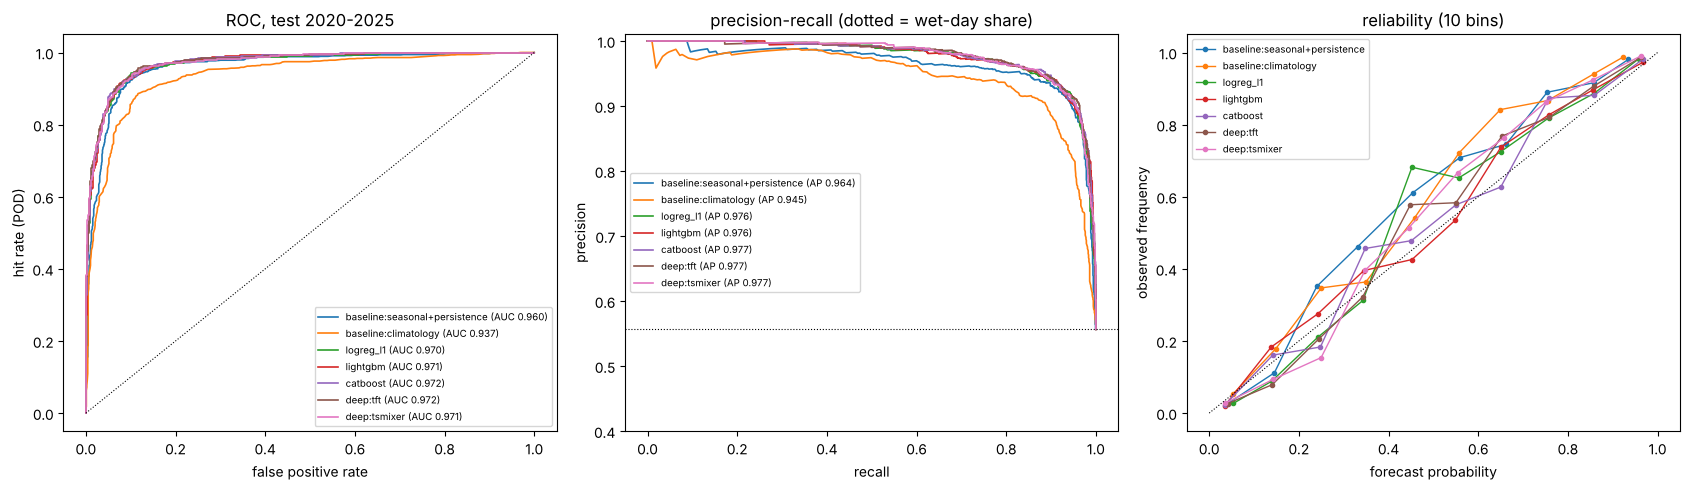

In [7]:
SEL_CLS = ["baseline:seasonal+persistence", "baseline:climatology", "logreg_l1", "lightgbm", "catboost", "deep:tft", "deep:tsmixer"]
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for m in SEL_CLS:
    p = pm_cls[m]
    fpr, tpr, _ = roc_curve(y_cls, p); pr, rc, _ = precision_recall_curve(y_cls, p)
    axes[0].plot(fpr, tpr, lw=1.2, label=f"{m} (AUC {compact1.loc[m, 'ROC_AUC']:.3f})")
    axes[1].plot(rc, pr, lw=1.2, label=f"{m} (AP {compact1.loc[m, 'PR_AUC']:.3f})")
    cal = M.calibration(y_cls, p)
    axes[2].plot(cal.mean_predicted, cal.observed_frequency, marker="o", ms=3, lw=1, label=m)
axes[0].plot([0, 1], [0, 1], "k:", lw=0.8); axes[2].plot([0, 1], [0, 1], "k:", lw=0.8)
axes[1].axhline(y_cls.mean(), color="k", ls=":", lw=0.8)
axes[0].set(xlabel="false positive rate", ylabel="hit rate (POD)", title="ROC, test 2020-2025")
axes[1].set(xlabel="recall", ylabel="precision", title="precision-recall (dotted = wet-day share)", ylim=(0.4, 1.01))
axes[2].set(xlabel="forecast probability", ylabel="observed frequency", title="reliability (10 bins)")
for a in axes: a.legend(fontsize=7)
fig.tight_layout(); save(fig, "07_test_roc_pr_reliability.png"); plt.show()

**Interpretation:**
- **ROC:** the learners' curves lie above seasonal + persistence everywhere, by a small margin (AUC 0.970–0.972 vs 0.960). Climatology is
  clearly worse.
- **PR:** precision stays above 0.95 up to ≈ 80 % recall.
- **Reliability:** the forecasts lie *above* the diagonal in the 0.2–0.7 range, so they **under-forecast** rain probability in the wetter
  test years. This is the expected regime-shift signature. ECE is 0.02–0.04 for the learners vs 0.05 for seasonal + persistence.

**Paper note:** *Test-period reliability diagrams showed a mild under-forecasting of rain probability (observed frequency above forecast
probability at intermediate probabilities), consistent with the wetter test regime.*

### Step 8 — Figures: predicted vs observed amounts and their distributions

**WHAT:** (a) density scatter (hexbin, log counts) of forecast vs observed mm for CatBoost Tweedie, hurdle, TiDE and seasonal +
persistence; (b) the distribution of daily amounts (quantile–quantile of observations vs each model's forecasts).

**Look for:** the "regression to the mean" signature — forecasts compressed into 0–30 mm while observations reach > 100 mm — and
which model has the most realistic spread.

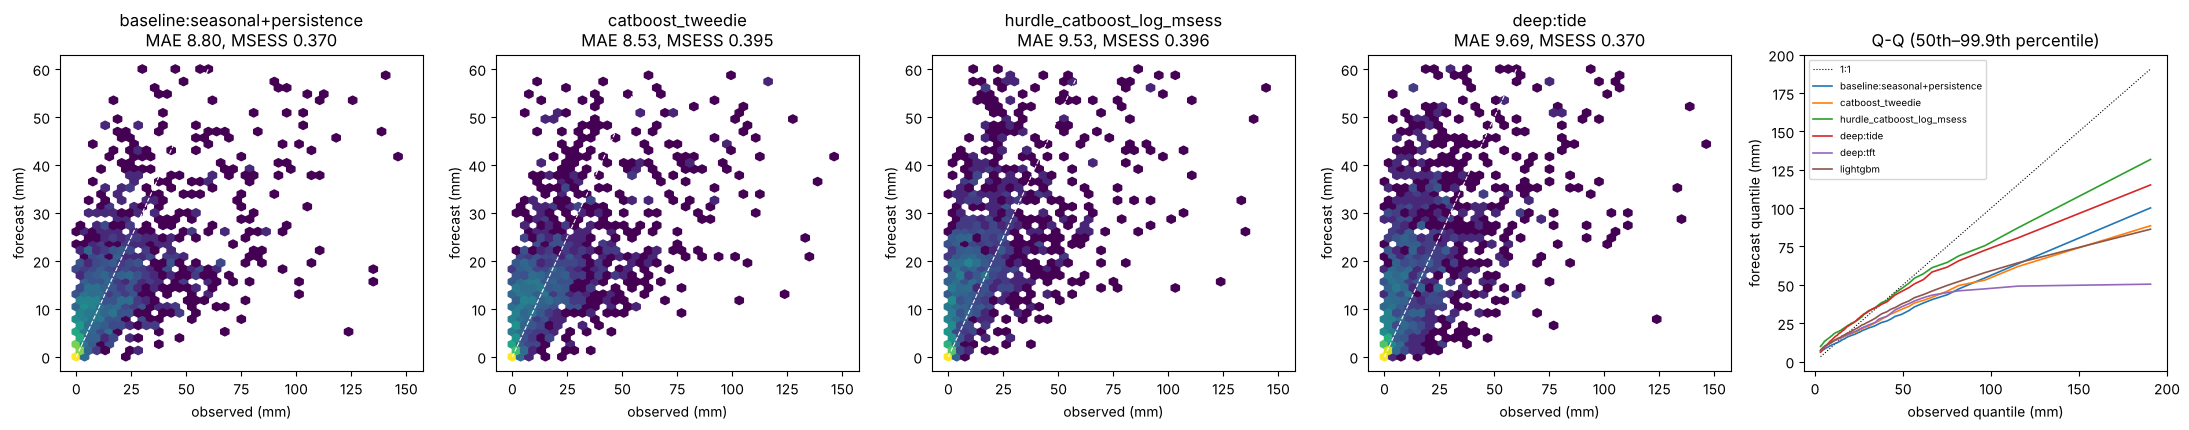

In [8]:
SEL_REG = ["baseline:seasonal+persistence", "catboost_tweedie", "hurdle_catboost_log_msess", "deep:tide", "deep:tft", "lightgbm"]
fig, axes = plt.subplots(1, 5, figsize=(22, 4.4))
for ax, m in zip(axes[:4], SEL_REG[:4]):
    hb = ax.hexbin(y_reg, pm_reg[m], gridsize=40, bins="log", extent=(0, 150, 0, 60), cmap="viridis", mincnt=1)
    ax.plot([0, 60], [0, 60], "w--", lw=0.8)
    ax.set(title=f"{m}\nMAE {compact2.loc[m, 'MAE']:.2f}, MSESS {compact2.loc[m, 'MSESS']:.3f}", xlabel="observed (mm)",
           ylabel="forecast (mm)")
qs = np.linspace(0.5, 0.999, 60)
axes[4].plot(np.quantile(y_reg, qs), np.quantile(y_reg, qs), "k:", lw=0.8, label="1:1")
for m in SEL_REG:
    axes[4].plot(np.quantile(y_reg, qs), np.quantile(pm_reg[m], qs), lw=1.2, label=m)
axes[4].set(xlabel="observed quantile (mm)", ylabel="forecast quantile (mm)", title="Q-Q (50th–99.9th percentile)")
axes[4].legend(fontsize=7)
fig.tight_layout(); save(fig, "07_test_pred_vs_obs.png"); plt.show()

**Interpretation:**
- **All point forecasts are compressed.** Observed days above 100 mm are forecast at 20–60 mm, and the Q–Q curves fall far below 1:1 above
  the 90th percentile.
- The mean-type forecasts (hurdle, TiDE) reach the highest quantiles (≈ 130 / 115 mm at the 99.9th percentile vs 190 mm observed). Tweedie,
  LightGBM and seasonal + persistence stay near 85–100 mm. TFT's quantile mean saturates at ≈ 50 mm.
- No next-day model built on a single grid cell's surface variables can predict the magnitude of extreme days.

**Paper note:** *All models strongly under-predicted the magnitude of extreme rainfall days (> 100 mm), with forecast distributions
compressed relative to observations.*

### Step 9 — Figures: the test years as a time series, with a zoom on the largest event

**WHAT:** (a) monthly totals 2020–2025: observed vs the summed daily forecasts of seasonal + persistence, CatBoost Tweedie,
hurdle and TiDE; (b) a 70-day daily zoom around the largest observed daily rainfall of the test period, with the amount forecasts
and, below, the rain probabilities of LightGBM and TFT.

**Look for:** whether models track the monsoon peaks, and how a next-day model behaves at an extreme (late, damped response).

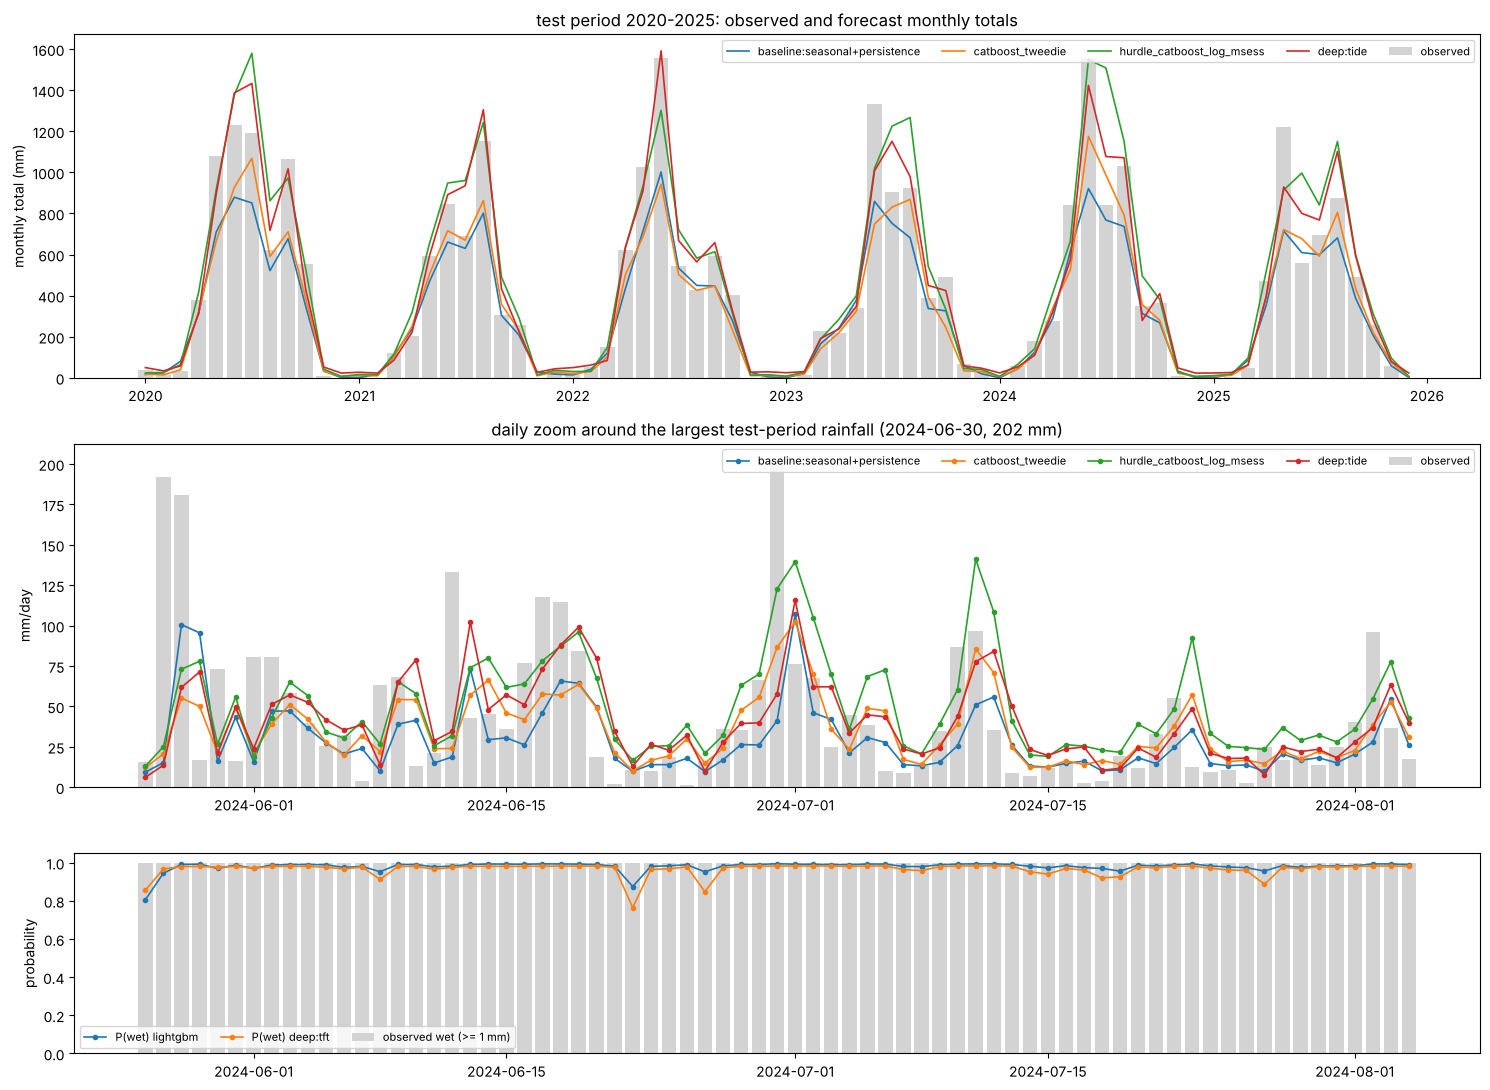

In [9]:
dates = S.target_dates(te)
mon = pd.DataFrame({"observed": y_reg.to_numpy(), **{m: pm_reg[m] for m in SEL_REG[:4]}}, index=dates).resample("MS").sum()
peak = dates[np.argmax(y_reg.to_numpy())]
win = (dates >= peak - pd.Timedelta(days=35)) & (dates <= peak + pd.Timedelta(days=35))
fig, axes = plt.subplots(3, 1, figsize=(15, 11), gridspec_kw={"height_ratios": [1.2, 1.2, 0.7]})
axes[0].bar(mon.index, mon.observed, width=25, color="lightgrey", label="observed")
for m in SEL_REG[:4]:
    axes[0].plot(mon.index, mon[m], lw=1.2, label=m)
axes[0].set(ylabel="monthly total (mm)", title="test period 2020-2025: observed and forecast monthly totals"); axes[0].legend(fontsize=8, ncol=5)
axes[1].bar(dates[win], y_reg.to_numpy()[win], color="lightgrey", label="observed")
for m in SEL_REG[:4]:
    axes[1].plot(dates[win], pm_reg[m][win], lw=1.2, marker=".", label=m)
axes[1].set(ylabel="mm/day", title=f"daily zoom around the largest test-period rainfall ({peak.date()}, {y_reg.max():.0f} mm)")
axes[1].legend(fontsize=8, ncol=5)
axes[2].bar(dates[win], y_cls.to_numpy()[win], color="lightgrey", label="observed wet (>= 1 mm)")
for m in ("lightgbm", "deep:tft"):
    axes[2].plot(dates[win], pm_cls[m][win], lw=1.2, marker=".", label=f"P(wet) {m}")
axes[2].set(ylabel="probability", ylim=(0, 1.05)); axes[2].legend(fontsize=8, ncol=3)
fig.tight_layout(); save(fig, "07_test_timeseries.png"); plt.show()

**Interpretation:**
- **Monthly totals:** the seasonal cycle and inter-annual differences are tracked. Seasonal + persistence and Tweedie under-estimate the
  monsoon peaks (e.g. June 2022 ≈ 1,550 mm observed vs ≈ 950–1,000 forecast). The hurdle and TiDE match or overshoot them
  (2020, 2023, 2024).
- **Zoom around the 202-mm day (2024-06-30):** no model anticipated it (forecasts 40–125 mm), and all of them produce their largest forecast
  on the *following* day (100–140 mm). This lag is the persistence mechanism: the models react to today's rain. The same happens after
  the 190-mm days of late May 2024.
- **Probabilities:** inside the monsoon P(wet) ≈ 0.95–1.0 almost every day, so occurrence is trivial here and the information is in the
  amounts.

**Paper note:** *During the monsoon, the models' rain-occurrence probabilities saturated near one and their amount forecasts lagged
extreme events by one day, reflecting a reliance on same-day rainfall persistence.*

### Step 10 — Figure and table: test skill by season (season of the target date)

**WHAT:** BSS, ROC-AUC and CSI (classification) and MAE, MSESS, bias (regression) by season — pre-monsoon (Mar–May), monsoon
(Jun–Sep), post-monsoon (Oct–Nov), winter (Dec–Feb) — for the selected models. References fitted on all seasons.

**Look for:** where the skill comes from (Stage 3: climatology ROC-AUC ≈ 0.70 within the monsoon) and where the models fail.

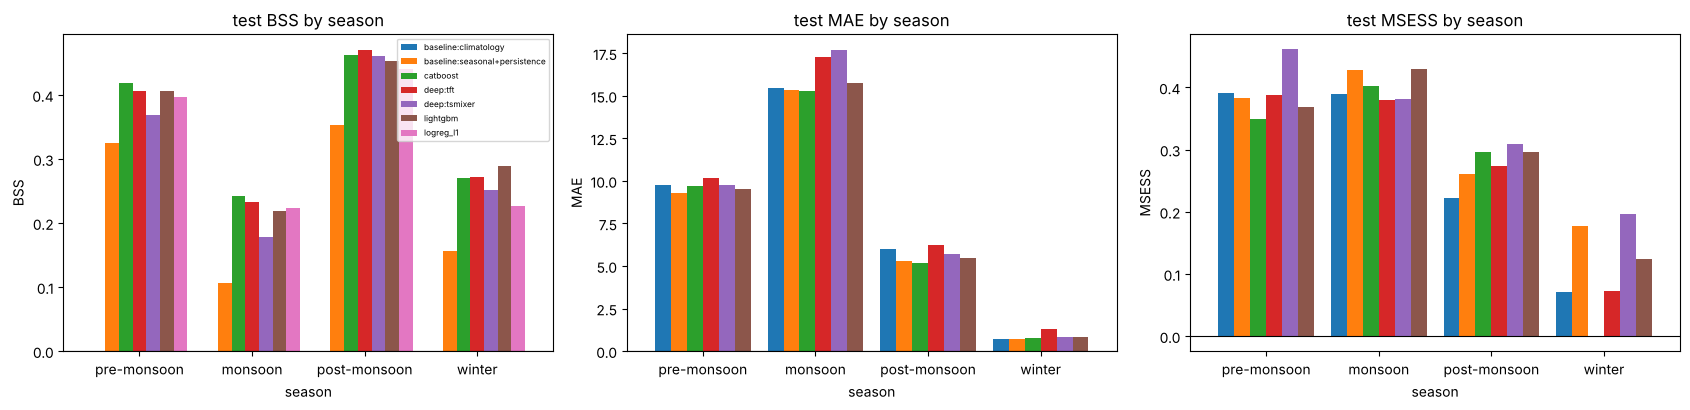

season,monsoon,post-monsoon,pre-monsoon,winter
model,,,,
baseline:climatology,0.000,0.000,0.000,0.000
baseline:seasonal+persistence,0.106,0.354,0.324,0.156
catboost,0.242,0.463,0.418,0.271
deep:tft,0.232,0.471,0.406,0.272
deep:tsmixer,0.179,0.460,0.369,0.252
lightgbm,0.219,0.453,0.406,0.289
logreg_l1,0.223,0.440,0.396,0.226


season,monsoon,post-monsoon,pre-monsoon,winter
model,,,,
baseline:seasonal+persistence,15.46,6.01,9.75,0.71
catboost_tweedie,15.35,5.28,9.31,0.73
deep:tft,15.26,5.17,9.73,0.80
deep:tide,17.27,6.26,10.15,1.28
hurdle_catboost_log_msess,17.71,5.70,9.78,0.83
lightgbm,15.73,5.47,9.52,0.85


days per season: {'pre-monsoon': 552, 'monsoon': 732, 'post-monsoon': 366, 'winter': 542}


In [10]:
sc = FR.by_season("cls", pm_cls, tm_cls, y_cls, te, SEL_CLS)
sr = FR.by_season("reg", pm_reg, {}, y_reg, te, SEL_REG)
sc.to_csv(TAB / "07_test_by_season_cls.csv", index=False); sr.to_csv(TAB / "07_test_by_season_reg.csv", index=False)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, (tab, met) in zip(axes, ((sc, "BSS"), (sr, "MAE"), (sr, "MSESS"))):
    piv = tab.pivot(index="season", columns="model", values=met).loc[list(FR.SEASONS)]
    piv.plot.bar(ax=ax, rot=0, width=0.85, legend=(met == "BSS"))
    ax.axhline(0, color="k", lw=0.8); ax.set(title=f"test {met} by season", ylabel=met)
axes[0].legend(fontsize=6)
fig.tight_layout(); save(fig, "07_test_by_season.png"); plt.show()
display(sc.pivot(index="model", columns="season", values="BSS").round(3)); display(sr.pivot(index="model", columns="season", values="MAE").round(2))
print("days per season:", sc.drop_duplicates("season").set_index("season").n_days.to_dict())

**Interpretation:** skill depends strongly on the season.
- **BSS** (vs the all-season climatology fitted on development years) is highest post-monsoon (0.44–0.47) and pre-monsoon (0.37–0.42).
  It is lowest in the **monsoon** (0.18–0.24; seasonal + persistence 0.11) and in winter (0.23–0.29, few wet days).
- **MAE** is dominated by the monsoon (15–18 mm vs < 1 mm in winter). In the monsoon Tweedie (15.35) and TFT (15.26) barely beat seasonal +
  persistence (15.46), while the hurdle (17.7) and TiDE (17.3) are clearly worse. Post-monsoon is where the learners gain most on MAE
  (Tweedie 5.28 vs 6.01).
- The transition seasons are where the predictors (humidity build-up, pressure) add information beyond persistence.

**Paper note:** *Skill was concentrated in the pre- and post-monsoon transition seasons, whereas during the monsoon the models added
little beyond seasonal persistence.*

### Step 11 — Red flags (rule 11) and audit

**WHAT:** (a) the pre-registered triggers on the test scores (BSS > 0.45, monsoon ROC-AUC > 0.90 at 1 mm, MSESS > 0.60);
(b) prediction files only from the confirmed run (manifest), test getter unlocked only in `tests/test_splits.py` and
`src/final_eval.py`; (c) development predictions still end on 2019-12-31.

In [11]:
t = pd.concat([raw_cls.assign(task="cls"), raw_reg.assign(task="reg")])
mon_auc = {m: FR.score("cls", y_cls[FR.season_of(te).eq("monsoon").to_numpy()], pm_cls[m][FR.season_of(te).eq("monsoon").to_numpy()],
                       0.5, {k: v[FR.season_of(te).eq("monsoon").to_numpy()] for k, v in FR.references(P["cls"][0]).items()},
                       te[FR.season_of(te).eq("monsoon").to_numpy()])["ROC_AUC"] for m in pm_cls}
print("max BSS %.3f | max MSESS %.3f | max monsoon ROC-AUC %.3f" % (t.BSS.max(), t.MSESS.max(), max(mon_auc.values())))
print("rule-11 hits:", int((t.BSS > 0.45).sum() + (t.MSESS > 0.60).sum() + sum(v > 0.90 for v in mon_auc.values())))
files = {f.stem for f in FE.TEST_DIR.glob("*.parquet")}
print("files on disk == files in manifest:", files == set(man["files"]))
Rep.test_set_audit()

max BSS 0.383 | max MSESS 0.433 | max monsoon ROC-AUC 0.899
rule-11 hits: 0
files on disk == files in manifest: True


{'OOF files checked': 425,
 'latest target date in any OOF file': '2019-12-31',
 'folds present in cv_results': [1, 2, 3, 4, 5],
 'files calling test_index(..., confirm_final=True)': ['src/final_report.py',
  'src/final_eval.py',
  'tests/test_splits.py']}

**Interpretation:**
- **(a) No rule-11 trigger:** max BSS 0.383, max MSESS 0.433. Max monsoon ROC-AUC is **0.899, just below the 0.90 trigger**, and was
  investigated: the test monsoons have only **31 dry days** (< 1 mm) in six years, so the monsoon AUC rests on 31 negatives. Seasonal +
  persistence reaches 0.79 and the learners 0.87–0.89 (development 0.81–0.85). Nothing in the pipeline changed since the freeze, and the
  leakage tests cover it. This is a small-sample statistic, not a leak.
- **(b)** The files on disk equal the manifest. The test getter is called only by `tests/test_splits.py`, `src/final_eval.py` and,
  after the run, `src/final_report.py`, which now refuses to read test labels unless the confirmed run's manifest exists (new test).
  Development OOF files still end on 2019-12-31.

**Paper note:** *No test score exceeded the pre-registered plausibility thresholds; monsoon discrimination is reported with its small
number of rain-free days.*

# Prompt 7.3 — Statistical comparison

### Step 12 — What the tests assume, and why not a paired t-test or McNemar

- **Paired monthly block bootstrap.** Resamples whole calendar months of the target date with replacement (the same months for both
  models of a pair, and for all models), recomputes the metric difference, and takes the 2.5/97.5 % percentiles. *Assumes* that
  dependence between days is mostly *within* a month and that months are roughly exchangeable — block resampling keeps the
  day-to-day autocorrelation (rain spells) inside each block. It gives CIs for *skill-score differences* (ΔBSS, ΔMSESS), which are
  ratios and have no simple analytic variance.
- **Diebold–Mariano.** Tests H₀: E[L_a − L_b] = 0 for the daily loss differential d_t (Brier, absolute or squared error). *Assumes*
  d_t is covariance-stationary with finite variance; its autocorrelation is handled by the **HAC (Newey–West / Bartlett) long-run
  variance** with bandwidth ⌊4(n/100)^(2/9)⌋ = 7 days for n = 2,192, and the **Harvey–Leybourne–Newbold** factor plus a Student-t
  reference corrects the small-sample over-rejection. It compares *forecasts*, not models (no assumption that either is correct).
- **Holm step-down.** Within each family (A: vs seasonal + persistence; B: vs the headline reference) × task × loss, the sorted
  p-values are multiplied by m, m−1, … and made monotone; controls the family-wise error rate at 5 % under *any* dependence
  between the tests (models are highly correlated, so Bonferroni-type control that needs no independence is appropriate).
- **Why not a paired t-test:** it assumes the n daily differences are *independent*. Daily rain has strong persistence
  (Stage 1: lag-1 autocorrelation of daily rain 0.58, still 0.24 at lag 7; wet/dry spells of days to weeks); the loss differentials inherit it, so the
  effective sample size is far below 2,192 and the naive standard error is too small → p-values too small (false discoveries).
- **Why not McNemar:** it compares two *yes/no* forecasts through discordant pairs and also assumes independent days; it discards
  the probabilistic information (Brier/BSS is our primary score) and depends on the arbitrary thresholds.

### Step 13 — Comparison table: effect sizes, 95 % CIs, DM statistics and Holm-adjusted p-values

**WHAT:** `FR.comparisons` for both tasks (seed-mean forecasts). Effects: **ΔBSS** = (Brier_ref − Brier_model) / Brier_climatology,
**ΔMSESS** analogously with squared error (> 0 = model better), **ΔMAE** = MAE_model − MAE_ref (< 0 = model better).

**Look for:** which models are *significantly better* than seasonal + persistence after Holm, and whether any model beats the
pre-declared headline references.

In [12]:
comp = pd.concat([FR.comparisons("cls", pm_cls, y_cls, te), FR.comparisons("reg", pm_reg, y_reg, te)], ignore_index=True)
comp.to_csv(TAB / "07_statistical_comparison.csv", index=False)
show = comp.assign(**{"CI": comp.ci_low.map("{:.3f}".format) + " .. " + comp.ci_high.map("{:.3f}".format)})
show = show[["family", "task", "loss", "model", "reference", "effect", "estimate", "CI", "DM", "p", "p_holm", "significant", "better"]]
FR.to_latex(show.round(4), TAB / "07_statistical_comparison.tex", "Paired comparisons on 2020--2025: effect size with 95\\% "
            "monthly block-bootstrap CI, Diebold--Mariano statistic (HAC, HLN-corrected) and Holm-adjusted p-value.", "tab:test_dm")
summary = comp.groupby(["family", "task", "loss", "reference"]).apply(
    lambda g: pd.Series({"models": len(g), "significantly better": int((g.significant & g.better).sum()),
                         "significantly worse": int((g.significant & ~g.better).sum())}), include_groups=False)
display(summary)
with pd.option_context("display.max_rows", 200):
    display(show.round(4))

models  significantly better  significantly worse
family task loss      reference                                                                       
A      cls  Brier     baseline:seasonal+persistence      17                    12                    5
       reg  abs_error baseline:seasonal+persistence      19                     0                   11
            sq_error  baseline:seasonal+persistence      19                     1                    6
B      cls  Brier     lightgbm                           17                     0                    6
       reg  abs_error catboost_tweedie                   19                     0                   16
            sq_error  hurdle_catboost_log_msess          19                     0                    4

,family,task,loss,model,reference,effect,estimate,CI,DM,p,p_holm,significant,better
0,A,cls,Brier,baseline:majority,baseline:seasonal+persistence,dBSS,-1.797e+00,-2.390 .. -1.387,31.526,0.000e+00,0.000e+00,True,False
1,A,cls,Brier,baseline:persistence,baseline:seasonal+persistence,dBSS,-1.382e-01,-0.207 .. -0.081,6.827,0.000e+00,0.000e+00,True,False
2,A,cls,Brier,baseline:climatology,baseline:seasonal+persistence,dBSS,-2.685e-01,-0.321 .. -0.213,8.154,0.000e+00,0.000e+00,True,False
3,A,cls,Brier,baseline:seasonal,baseline:seasonal+persistence,dBSS,-2.799e-01,-0.329 .. -0.225,8.812,0.000e+00,0.000e+00,True,False
4,A,cls,Brier,logreg_none,baseline:seasonal+persistence,dBSS,9.100e-02,0.059 .. 0.117,-5.336,0.000e+00,0.000e+00,True,True
5,A,cls,Brier,logreg_l2,baseline:seasonal+persistence,dBSS,8.970e-02,0.067 .. 0.111,-5.880,0.000e+00,0.000e+00,True,True
6,A,cls,Brier,logreg_l1,baseline:seasonal+persistence,dBSS,8.230e-02,0.061 .. 0.101,-5.492,0.000e+00,0.000e+00,True,True
7,A,cls,Brier,logreg_enet,baseline:seasonal+persistence,dBSS,8.940e-02,0.066 .. 0.110,-5.930,0.000e+00,0.000e+00,True,True
8,A,cls,Brier,sgd_logloss,baseline:seasonal+persistence,dBSS,9.100e-02,0.068 .. 0.112,-5.909,0.000e+00,0.000e+00,True,True
9,A,cls,Brier,random_forest,baseline:seasonal+persistence,dBSS,6.990e-02,0.048 .. 0.091,-4.726,0.000e+00,0.000e+00,True,True


**Interpretation (Holm-corrected DM tests; effect sizes with bootstrap CIs):**
- **Classification vs seasonal + persistence:** all 10 classical models, TFT and TSMixer are **significantly better** (ΔBSS +0.07 to +0.11,
  all CIs above 0, Holm p < 0.001). TiDE is significantly worse (−0.042).
- **Classification vs the headline LightGBM:** **no model is significantly better.** CatBoost +0.008 [−0.002, 0.018], TFT +0.004, XGBoost
  +0.001. The tuned linear models are −0.009 to −0.017 (n.s.). Only TiDE and the baselines are significantly worse. **Gradient boosting,
  tuned logistic regression and TFT are statistically indistinguishable.**
- **Regression MAE vs seasonal + persistence:** **no model is significantly better after Holm.** Tweedie −0.26 mm has a bootstrap CI of
  [−0.49, −0.03] that excludes 0, but its DM p = 0.023 becomes 0.16 after Holm over 19 comparisons. TFT is −0.19 (n.s.). The linear models,
  hurdle, TSMixer and TiDE are significantly *worse* (+0.4 to +0.9 mm).
- **MAE vs the headline Tweedie:** every other learner except TFT and MLP is significantly worse (+0.20 to +1.15 mm). Seasonal + persistence is
  not significantly different.
- **Squared error (MSESS):** only TSMixer's seed-mean forecast is significantly better than seasonal + persistence (+0.047 [0.019, 0.076]).
  Against the headline hurdle, no model differs significantly, and the boosters, Tweedie, TFT and TiDE are all within ±0.03.
- **Bootstrap vs DM:** the two can disagree near the margin (Tweedie MAE). The bootstrap CI is a per-comparison 95 % interval; the Holm
  p-value controls the family-wise error over 19 comparisons. We report both and claim significance only after Holm.

**Paper note:** *After Holm correction, all classical classifiers and two deep classifiers beat seasonal persistence in Brier score
but were indistinguishable from each other, whereas no regression model significantly beat seasonal persistence in MAE.*

### Step 14 — Forest plots and significance matrix

**WHAT:** for each family × loss, the effect with its CI per model (filled = significant after Holm); and a compact matrix
(rows = models, columns = comparisons) of significant wins (+), losses (−) and non-significant differences (·).

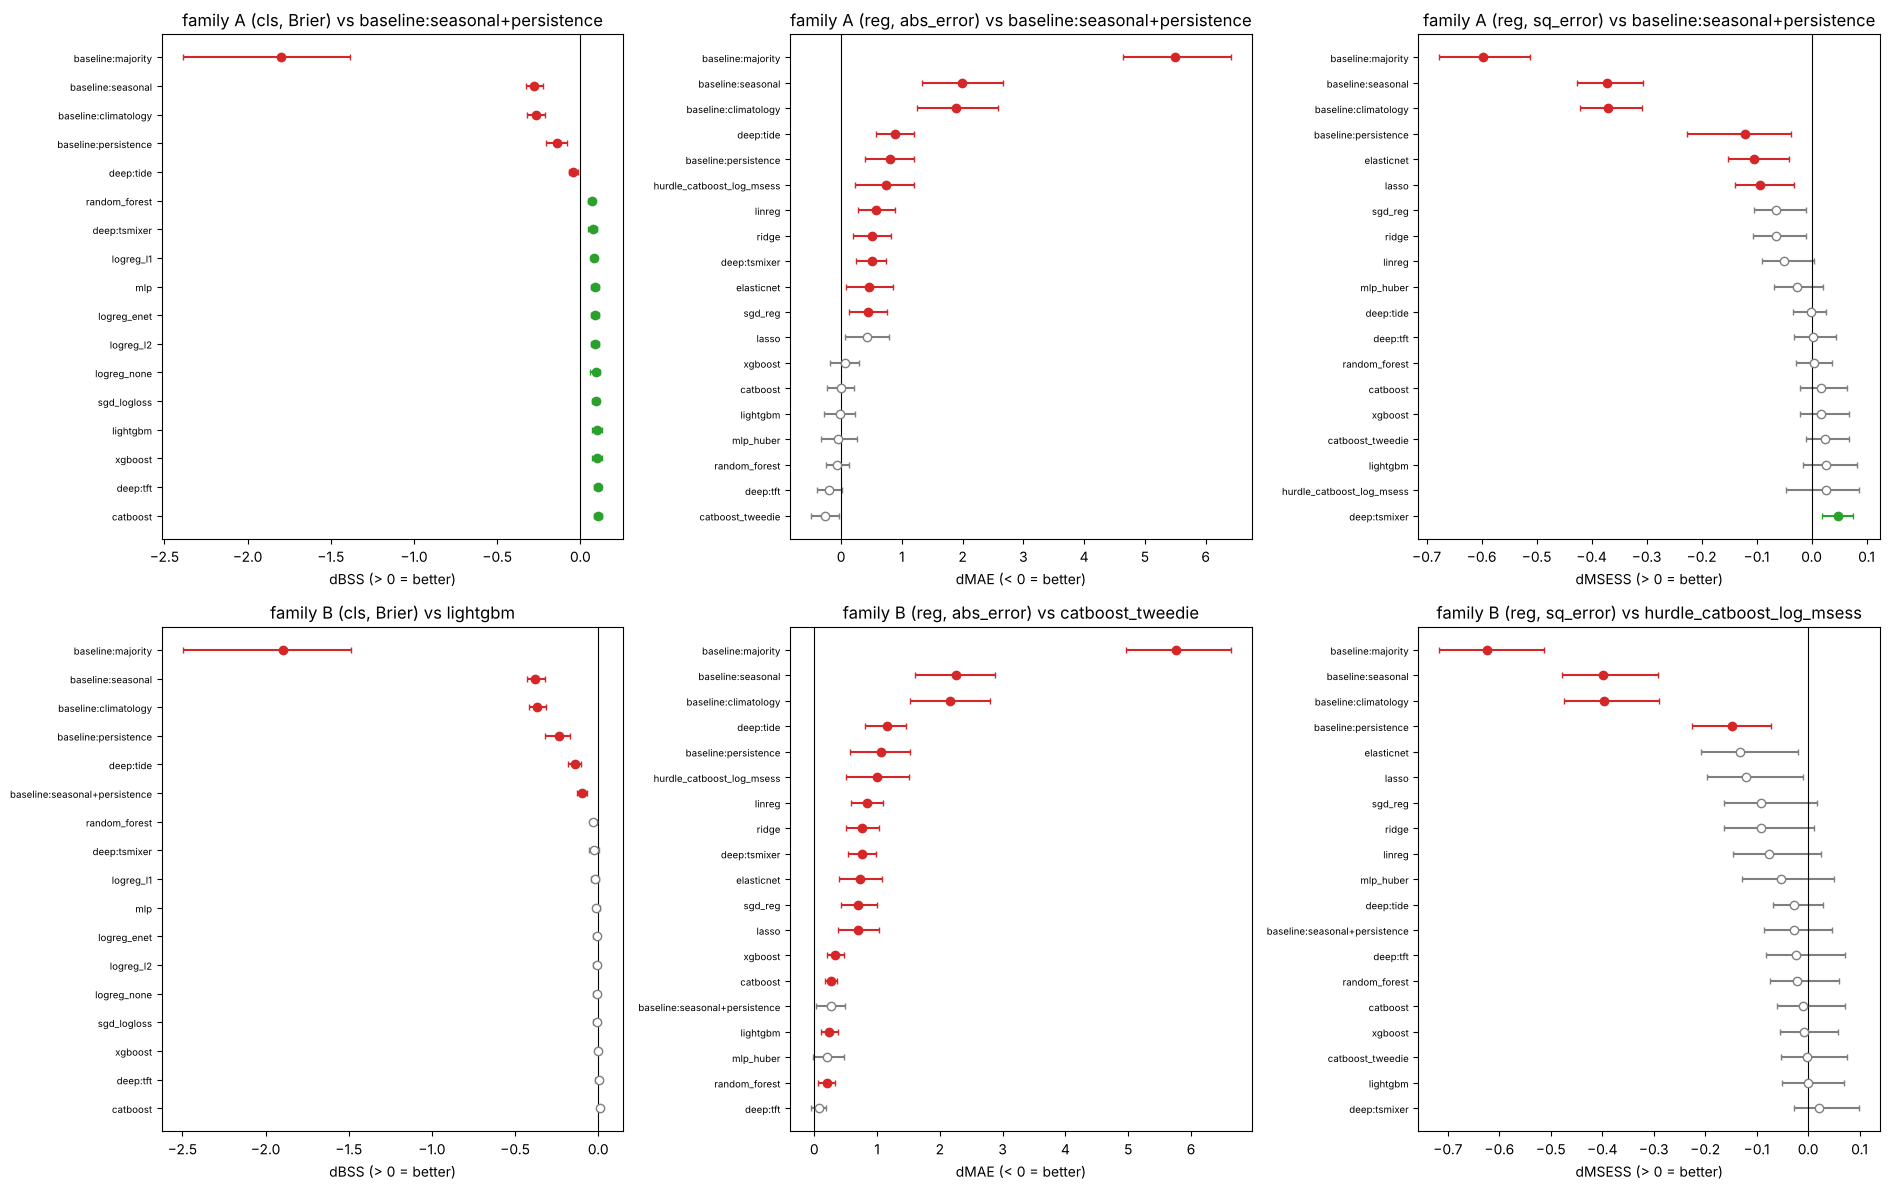

family                                 A                        B                   
loss                               Brier abs_error sq_error Brier abs_error sq_error
task model                                                                          
cls  baseline:climatology              −       ref      ref     −       ref      ref
     baseline:majority                 −       ref      ref     −       ref      ref
     baseline:persistence              −       ref      ref     −       ref      ref
     baseline:seasonal                 −       ref      ref     −       ref      ref
     baseline:seasonal+persistence   ref       ref      ref     −       ref      ref
     catboost                          +       ref      ref     ·       ref      ref
     deep:tft                          +       ref      ref     ·       ref      ref
     deep:tide                         −       ref      ref     −       ref      ref
     deep:tsmixer                      +       ref      ref     ·       ref      ref
     lightgbm                          +       ref      ref   ref       ref      ref
     logreg_enet                       +       ref      ref     ·       ref      ref
     logreg_l1                         +       ref      ref     ·       ref      ref
     logreg_l2                         +       ref      ref     ·       ref      ref
     logreg_none                       +       ref      ref     ·       ref      ref
     mlp                               +       ref      ref     ·       ref      ref
     random_forest                     +       ref      ref     ·       ref      ref
     sgd_logloss                       +       ref      ref     ·       ref      ref
     xgboost                           +       ref      ref     ·       ref      ref
reg  baseline:climatology            ref         −        −   ref         −        −
     baseline:majority               ref         −        −   ref         −        −
     baseline:persistence            ref         −        −   ref         −        −
     baseline:seasonal               ref         −        −   ref         −        −
     baseline:seasonal+persistence   ref       ref      ref   ref         ·        ·
     catboost                        ref         ·        ·   ref         −        ·
     catboost_tweedie                ref         ·        ·   ref       ref        ·
     deep:tft                        ref         ·        ·   ref         ·        ·
     deep:tide                       ref         −        ·   ref         −        ·
     deep:tsmixer                    ref         −        +   ref         −        ·
     elasticnet                      ref         −        −   ref         −        ·
     hurdle_catboost_log_msess       ref         −        ·   ref         −      ref
     lasso                           ref         ·        −   ref         −        ·
     lightgbm                        ref         ·        ·   ref         −        ·
     linreg                          ref         −        ·   ref         −        ·
     mlp_huber                       ref         ·        ·   ref         ·        ·
     random_forest                   ref         ·        ·   ref         −        ·
     ridge                           ref         −        ·   ref         −        ·
     sgd_reg                         ref         −        ·   ref         −        ·
     xgboost                         ref         ·        ·   ref         −        ·

In [13]:
groups = comp.groupby(["family", "task", "loss"])
fig, axes = plt.subplots(2, 3, figsize=(19, 12))
for ax, ((fam, task, loss), g) in zip(axes.ravel(), groups):
    g = g.sort_values("estimate", ascending=(loss == "abs_error")).reset_index(drop=True)
    for k, r in g.iterrows():
        col = "tab:green" if (r.significant and r.better) else "tab:red" if r.significant else "tab:grey"
        ax.errorbar(r.estimate, k, xerr=[[r.estimate - r.ci_low], [r.ci_high - r.estimate]], fmt="o" if r.significant else "o",
                    mfc=col if r.significant else "white", color=col, capsize=2)
    ax.axvline(0, color="k", lw=0.8)
    ax.set(yticks=range(len(g)), yticklabels=g.model, title=f"family {fam} ({task}, {loss}) vs {g.reference.iloc[0]}",
           xlabel=g.effect.iloc[0] + (" (< 0 = better)" if loss == "abs_error" else " (> 0 = better)"))
    ax.tick_params(axis="y", labelsize=7)
fig.tight_layout(); save(fig, "07_test_forest.png"); plt.show()
comp["cell"] = np.where(~comp.significant, "·", np.where(comp.better, "+", "−"))
matrix = comp.pivot_table(index=["task", "model"], columns=["family", "loss"], values="cell", aggfunc="first").fillna("ref")
matrix.to_csv(TAB / "07_significance_matrix.csv"); FR.to_latex(matrix, TAB / "07_significance_matrix.tex",
    "Holm-corrected Diebold--Mariano results on 2020--2025 (+ significantly better, $-$ significantly worse, $\\cdot$ n.s.).",
    "tab:test_matrix")
matrix

**Interpretation:**
- **The classification rows are almost uniform:** + against seasonal + persistence and · against LightGBM. TiDE and the baselines are the
  exceptions.
- **The regression matrix is mostly − and ·:** the amount problem is where models fail to separate from persistence.
- The forest plots show why. Classification effects are many CI-widths from zero, while regression effects straddle it, with CIs of
  ±0.2–0.5 mm against differences of 0.1–0.3 mm.

All tables are saved as CSV and LaTeX (`07_statistical_comparison.*`, `07_significance_matrix.*`, `07_table1_classification.*`,
`07_table2_regression.*`).

**Paper note:** *Significant differences were systematic for rain occurrence and largely absent for rainfall amounts (Figure: forest
plots; Table: significance matrix).*

### SKEPTICAL-REVIEWER — test results

| # | Criticism | Answer / status |
|---|---|---|
| 1 | *"BSS 0.37 on test is suspiciously higher than 0.265 in development."* | Investigated: every model *including the baselines* rose by ≈ 0.10 (seasonal + persistence 0.18 → 0.27). The climatology reference, fitted on drier years, is a worse forecast in the wetter test years, so skill against it is inflated. BSS vs seasonal + persistence rose only modestly (≈ 0.10 → 0.11–0.15). Below the rule-11 trigger. |
| 2 | *"Skill against reanalysis rain is not skill against real rain."* | Agreed. The pre-registered IMERG check shows BSS ≈ 0 vs seasonal + persistence when scored on IMERG (ROC-AUC still 0.92). This is the paper's main limitation and is stated in the abstract. |
| 3 | *"You report Tweedie as the best MAE model, but it is not significant."* | Correct: −0.26 mm, bootstrap CI excludes 0, Holm-adjusted DM p = 0.16. We say "lowest MAE, not significantly better than seasonal persistence". |
| 4 | *"Seed-mean forecasts are an ensemble; per-seed models are worse."* | Pre-registered, and per-seed mean ± std are reported. For TSMixer the difference matters (seed 1 failed: MAE 13.2); the seed-mean result is labelled as a 5-member ensemble. |
| 5 | *"The broken TSMixer seed was known before the test."* | Yes (DECISIONS 7.3). It was kept to avoid a post-hoc rule change, and its failure is reported. |
| 6 | *"The DM test assumes stationarity, but the test period has a regime shift."* | The loss differential between two forecasts is far more stationary than the series itself. Months are resampled as blocks, and the conclusions agree with the bootstrap. The 6-year test window is one realisation — a single site and period. |
| 7 | *"Only one grid cell."* | Yes: single-site results; generalisation to other basins is untested. |
| 8 | *"Monsoon ROC-AUC 0.899 is almost a trigger."* | Investigated: 31 rain-free monsoon days in six years. Reported with its sample size. |
| 9 | *"Did anything change after the freeze?"* | No model, threshold or protocol change. Post-run code changes (analysis module; `by_season` metric call; manifest guard; audit test) are analysis-only and listed in DECISIONS 7.5. |

### Stage 7 — summary

1. One-shot run from the freeze commit; 126 prediction files, manifest verified.
2. **Classification:** all classical models, TFT and TSMixer beat seasonal + persistence significantly (ΔBSS +0.07 to +0.11; BSS 0.34–0.38).
   They are statistically indistinguishable from each other; TiDE fails.
3. **Regression:** Tweedie has the lowest MAE (8.53 vs 8.80), but nothing beats seasonal + persistence after Holm. The mean-type models
   trade MAE for bias and heavy-rain detection. Extremes are strongly under-predicted and lag by a day.
4. The development ranking transfers (ρ 0.88–0.95), while absolute levels shift with the wetter regime.
5. Against IMERG the probabilistic skill largely disappears (BSS ≈ 0 vs seasonal + persistence, ROC-AUC 0.92).

---

## END-OF-STAGE 7 — five things you must be able to explain in the paper

1. **How the test result was protected:** freeze commit, frozen thresholds/trees/epochs/smearing, a one-shot run with manifest and hash
   checks, no selection on test, all models reported.
2. **What the models achieve on new years:** rain occurrence clearly better than seasonal persistence (ΔBSS ≈ +0.10, robust after Holm);
   rain amounts not significantly better in MAE. Simple tuned linear models are as good as boosters and TFT for occurrence.
3. **Why absolute scores rose on test:** the reference forecasts degrade in the wetter regime (BSS vs climatology inflated), so skill vs
   seasonal persistence is the fair comparison; the ranking is stable.
4. **The statistical method:** DM tests on daily loss differentials with HAC variance and the HLN correction, Holm within pre-declared
   families, monthly block-bootstrap CIs — and why independent-day tests (t-test, McNemar) would overstate significance.
5. **The limits:** skill against independent IMERG rain is small (reanalysis self-consistency), extremes are under-predicted and lagged,
   and the results come from one grid cell and a six-year test period.

## Check your understanding (3 questions)
1. CatBoost Tweedie's MAE improvement over seasonal persistence has a bootstrap 95 % CI of [−0.49, −0.03] mm, yet its Holm-adjusted DM
   p-value is 0.16. Why can both be true, and which statement belongs in the abstract?
2. Every model's BSS vs climatology rose by about 0.10 from development to test, including the baselines. Explain the mechanism, and why
   BSS vs seasonal persistence is the more honest headline here.
3. Scored against IMERG, the frozen forecasts keep ROC-AUC ≈ 0.92 but lose almost all Brier skill. What does that tell you about
   discrimination vs calibration, and what would you need to do to get usable probabilities for IMERG-observed rain?